# SLOPE vs GMM decoding: how the comparison is made

This notebook walks through the comparison behind Fig. 5 of the paper (and Table S1/S2, Fig. S2 of the
supplement). The computation lives in [`analysis/fair_comparison.py`](../analysis/fair_comparison.py); the paper
figure is drawn by [`analysis/make_fig_decoding.py`](../analysis/make_fig_decoding.py). Here we only call those
functions and plot intermediate steps.

Needs the decoded data: `uv run python figshare_download.py --dataset ppm_20ghz_decoded ppm_10ghz_decoded`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
from analysis.datasets import get, decode_path
from analysis.fair_comparison import (load_decode, event_arrays, gmm_predict, slope_predict, correct,
                                      OFFSETS, analyze, mcnemar)

DATASET, DB = "20", 28          # try "10" / 32
cfg = get(DATASET)
decode = load_decode(decode_path(cfg, DB))
T = cfg["laser_time_ps"] or decode.set_data["laser_time"] * 1e12
gm = decode.gm_data.gm_list[cfg["gm_idx"]]
ev = event_arrays(decode)
print(f"{cfg['tag']} {DB} dB: slot {T:.2f} ps, {len(ev['tag'])} detections in {ev['stream'].max()+1} repetitions, "
      f"{ev['n_missing']} empty frames, GMM with {len(gm.weights)} components")

20GHz 28 dB: slot 50.00 ps, 33918 detections in 5 repetitions, 10767 empty frames, GMM with 25 components


## 1. Both decoders get a timing offset

Each decoder may shift its slot grid by a fraction of a slot. The original 2023 analysis scanned this offset
for the GMM decoder only; the SLOPE decoder was always evaluated at offset 0, which is the dotted vertical line.
Scanning both shows how much of the original GMM advantage came from that asymmetry.

SLOPE: error at offset 0 = 0.0565, best = 0.0540 at +0.0950 slots
GMM:   best = 0.0473 at -0.0600 slots


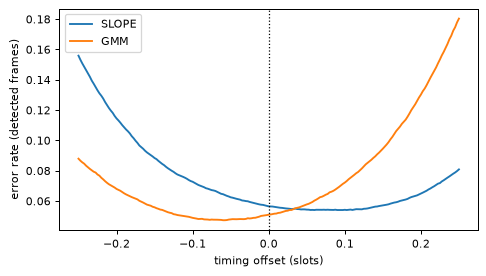

In [2]:
acc_slope = [correct(ev, slope_predict(ev, o, T)).mean() for o in OFFSETS]
acc_gmm = [correct(ev, gmm_predict(ev, gm, T, o)).mean() for o in OFFSETS]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(OFFSETS, 1 - np.array(acc_slope), label="SLOPE")
ax.plot(OFFSETS, 1 - np.array(acc_gmm), label="GMM")
ax.axvline(0, color="k", ls=":", lw=1)
ax.set_xlabel("timing offset (slots)"); ax.set_ylabel("error rate (detected frames)"); ax.legend()
print(f"SLOPE: error at offset 0 = {1-acc_slope[len(OFFSETS)//2]:.4f}, best = {1-max(acc_slope):.4f} at {OFFSETS[np.argmax(acc_slope)]:+.4f} slots")
print(f"GMM:   best = {1-max(acc_gmm):.4f} at {OFFSETS[np.argmax(acc_gmm)]:+.4f} slots")

## 2. Offsets are chosen on held-out data

The transmission was repeated five times. For each repetition, both offsets are chosen on the other four and
then applied to it, so no offset is tuned on the detections it is scored on.

In [3]:
r = analyze(decode, cfg["gm_idx"], cfg["laser_time_ps"], keep_events=True)
print("repetition  GMM offset  SLOPE offset (slots)")
for s, og, os_ in r["cv_offsets"]:
    print(f"    {s}        {og:+.4f}      {os_:+.4f}")
print(f"\nerrors: SLOPE {r['slope_errors']}, GMM {r['gmm_errors']} of {r['n_detected']} detected frames "
      f"(old one-sided scheme: SLOPE {r['legacy_slope_errors']}, GMM {r['legacy_gmm_errors']})")

repetition  GMM offset  SLOPE offset (slots)
    0        -0.0600      +0.0925
    1        -0.0600      +0.1025
    2        -0.0575      +0.0675
    3        -0.0575      +0.0550
    4        -0.0575      +0.1025

errors: SLOPE 1855, GMM 1608 of 33918 detected frames (old one-sided scheme: SLOPE 1915, GMM 1605)


## 3. A paired test

Both decoders classify the same detections, so the right test looks only at detections where they disagree
(exact McNemar test): *b* fixed by the GMM, *c* broken by it.

In [4]:
e = r["_events"]
b, c, p = mcnemar(e["gmm_ok"], e["slope_ok"])
print(f"GMM correct & SLOPE wrong: b = {b};  GMM wrong & SLOPE correct: c = {c};  p = {p:.2g}")
print(f"relative error reduction {100*r['reduction']:.1f}% (95% bootstrap CI {100*r['reduction_ci95'][0]:.1f} to {100*r['reduction_ci95'][1]:.1f}%)")
print(f"adjacent-slot errors: SLOPE {r['slope_adjacent_errors']}, GMM {r['gmm_adjacent_errors']}; "
      f"the rest (dark counts, dead-time tags) are common to both")

GMM correct & SLOPE wrong: b = 506;  GMM wrong & SLOPE correct: c = 259;  p = 2.9e-19
relative error reduction 13.3% (95% bootstrap CI 10.6 to 15.9%)
adjacent-slot errors: SLOPE 1822, GMM 1576; the rest (dark counts, dead-time tags) are common to both


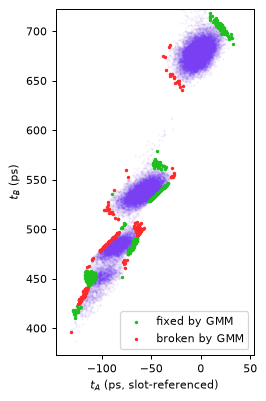

In [5]:
# where the disagreements are, relative to the true slot (cf. Fig. 5c,d)
x = e["xy"][:, 0] - T * e["true"]; y = e["xy"][:, 1] - T * e["true"]
g, s_ = e["gmm_ok"], e["slope_ok"]
fig, ax = plt.subplots(figsize=(4, 5))
ax.scatter(x[g & s_], y[g & s_], s=1, alpha=0.05, color="#7a3ff2", rasterized=True)
ax.scatter(x[g & ~s_], y[g & ~s_], s=3, color="#1fbf1f", label="fixed by GMM")
ax.scatter(x[~g & s_], y[~g & s_], s=3, color="#ff2b2b", label="broken by GMM")
cx, cy = np.median(x[g]), np.median(y[g])
ax.set_xlim(cx - 2*T, cx + 2*T); ax.set_ylim(cy - 3.5*T, cy + 3.5*T); ax.set_aspect("equal")
ax.set_xlabel("$t_A$ (ps, slot-referenced)"); ax.set_ylabel("$t_B$ (ps)"); ax.legend(loc="lower right")

## 4. All attenuations

`fair_comparison.json` holds the same numbers for every attenuation (written by `scripts/run_all.sh`). The
mean photon number is the attenuator-law calibration of `make_fig_decoding.py`.

(-60.0, 80.0)

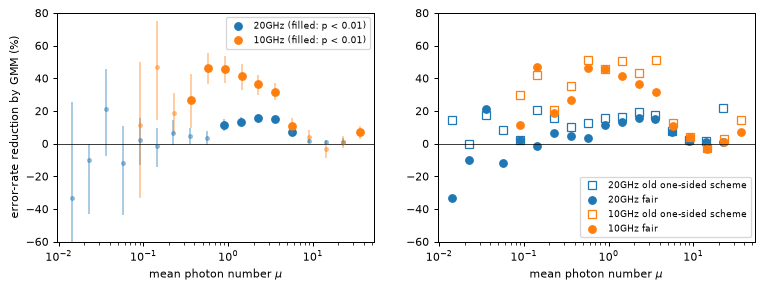

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3), sharex=True)
for key, color in [("20", "C0"), ("10", "C1")]:
    c_ = get(key)
    fair = json.loads(open(c_["fair"]).read())
    mu = {r_["db"]: r_["mu"] for r_ in json.loads(open(c_["table"]).read())["rows"]}
    rows = [(mu[int(float(k))], v) for k, v in fair.items() if v["reduction"] is not None]
    m = np.array([a for a, _ in rows]); red = np.array([100*v["reduction"] for _, v in rows])
    ci = np.array([[100*v["reduction_ci95"][0], 100*v["reduction_ci95"][1]] for _, v in rows])
    sig = np.array([v["mcnemar_p"] < 0.01 for _, v in rows])
    axs[0].errorbar(m, red, yerr=[red - ci[:, 0], ci[:, 1] - red], fmt="o", color=color, ms=3, alpha=0.4)
    axs[0].plot(m[sig], red[sig], "o", color=color, label=f"{c_['tag']} (filled: p < 0.01)")
    legacy = np.array([100*(1 - v["legacy_gmm_errors"]/v["legacy_slope_errors"]) for _, v in rows])
    axs[1].plot(m, legacy, "s", mfc="none", color=color, label=f"{c_['tag']} old one-sided scheme")
    axs[1].plot(m, red, "o", color=color, label=f"{c_['tag']} fair")
for ax in axs:
    ax.set_xscale("log"); ax.axhline(0, color="k", lw=0.6); ax.set_xlabel(r"mean photon number $\mu$"); ax.legend(fontsize=7)
axs[0].set_ylabel("error-rate reduction by GMM (%)"); axs[0].set_ylim(-60, 80); axs[1].set_ylim(-60, 80)